In [ ]:
from google.colab import files

files.download('demand_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.listdir())

['.config', 'demand_model.pkl', 'ERP_AI_Inventory_Dataset_750.csv', 'sample_data']


In [ ]:
joblib.dump(model, 'demand_model.pkl')

print("Model saved successfully!")

Model saved successfully!


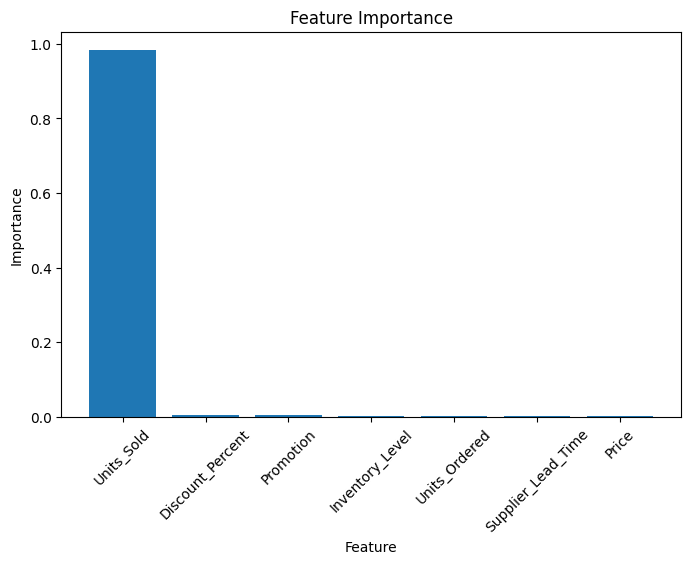

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel("Feature")
plt.ylabel("Importance")

plt.title("Feature Importance")

plt.xticks(rotation=45)

plt.show()

In [ ]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
1,Units_Sold,0.983642
5,Discount_Percent,0.004909
6,Promotion,0.004159
0,Inventory_Level,0.002740
2,Units_Ordered,0.002396
3,Supplier_Lead_Time,0.001090
4,Price,0.001065


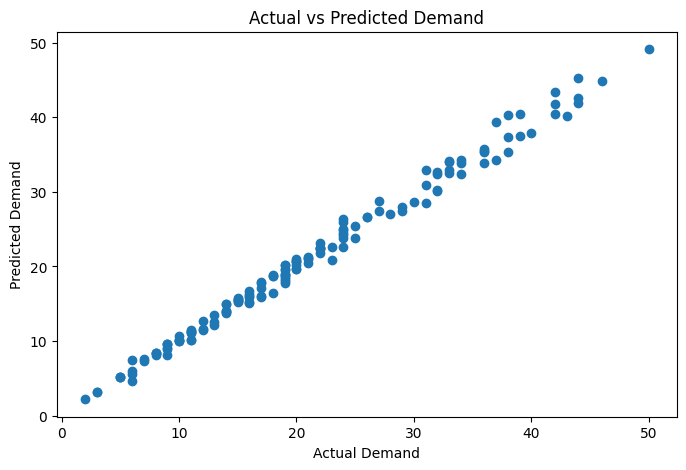

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")

plt.title("Actual vs Predicted Demand")

plt.show()

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 0.7687333333333332
RMSE: 1.0073718280754131
R2 Score: 0.991394639814483


In [ ]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[21.26 10.15 16.26 15.28 28.79 10.13 20.92 19.7  49.12 15.17]


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [ ]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 600
Testing records: 150


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
X = df[['Inventory_Level',
        'Units_Sold',
        'Units_Ordered',
        'Supplier_Lead_Time',
        'Price',
        'Discount_Percent',
        'Promotion']]

y = df['Demand_Forecast']

In [ ]:
print(df.isnull().sum())

Date                  0
Product_ID            0
Product_Name          0
Category              0
Store_ID              0
Inventory_Level       0
Units_Sold            0
Units_Ordered         0
Supplier_Lead_Time    0
Price                 0
Discount_Percent      0
Promotion             0
Demand_Forecast       0
dtype: int64


In [ ]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 750


In [ ]:
df.describe()

,Inventory_Level,Units_Sold,Units_Ordered,Supplier_Lead_Time,Price,Discount_Percent,Promotion,Demand_Forecast
count,750.000000,750.000000,750.000000,750.000000,750.00000,750.000000,750.000000,750.000000
mean,63.548000,18.265333,35.497333,5.340000,45800.00000,5.840000,0.664000,22.110667
std,30.795067,9.603362,13.059967,1.616132,70987.17423,5.347822,0.472654,11.075407
min,5.000000,1.000000,10.000000,2.000000,3500.00000,0.000000,0.000000,2.000000
25%,37.000000,11.000000,26.000000,4.000000,7500.00000,0.000000,0.000000,14.000000
50%,61.000000,17.000000,35.000000,5.000000,16250.00000,5.000000,1.000000,21.000000
75%,88.750000,25.000000,43.000000,7.000000,55000.00000,10.000000,1.000000,29.000000
max,135.000000,46.000000,95.000000,9.000000,250000.00000,15.000000,1.000000,54.000000


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(df.isnull().sum())

Date                  0
Product_ID            0
Product_Name          0
Category              0
Store_ID              0
Inventory_Level       0
Units_Sold            0
Units_Ordered         0
Supplier_Lead_Time    0
Price                 0
Discount_Percent      0
Promotion             0
Demand_Forecast       0
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Date                750 non-null    object
 1   Product_ID          750 non-null    object
 2   Product_Name        750 non-null    object
 3   Category            750 non-null    object
 4   Store_ID            750 non-null    object
 5   Inventory_Level     750 non-null    int64 
 6   Units_Sold          750 non-null    int64 
 7   Units_Ordered       750 non-null    int64 
 8   Supplier_Lead_Time  750 non-null    int64 
 9   Price               750 non-null    int64 
 10  Discount_Percent    750 non-null    int64 
 11  Promotion           750 non-null    int64 
 12  Demand_Forecast     750 non-null    int64 
dtypes: int64(8), object(5)
memory usage: 76.3+ KB


In [ ]:
print(df.columns.tolist())

['Date', 'Product_ID', 'Product_Name', 'Category', 'Store_ID', 'Inventory_Level', 'Units_Sold', 'Units_Ordered', 'Supplier_Lead_Time', 'Price', 'Discount_Percent', 'Promotion', 'Demand_Forecast']


In [ ]:
df.tail()

,Date,Product_ID,Product_Name,Category,Store_ID,Inventory_Level,Units_Sold,Units_Ordered,Supplier_Lead_Time,Price,Discount_Percent,Promotion,Demand_Forecast
745,2026-03-16,P006,Headset,Accessories,S002,39,27,38,4,12000,10,1,31
746,2026-03-16,P007,Webcam,Accessories,S003,62,15,31,6,18000,15,1,19
747,2026-03-16,P008,Router,Networking,S004,82,8,29,8,14500,5,1,11
748,2026-03-16,P009,USB_Drive,Storage,S001,86,35,43,2,4500,0,0,37
749,2026-03-16,P010,External_HDD,Storage,S002,115,11,24,5,28000,0,0,12


In [ ]:
df.head()

,Date,Product_ID,Product_Name,Category,Store_ID,Inventory_Level,Units_Sold,Units_Ordered,Supplier_Lead_Time,Price,Discount_Percent,Promotion,Demand_Forecast
0,2026-01-01,P001,Laptop,Electronics,S001,42,8,20,5,250000,5,1,10
1,2026-01-02,P001,Laptop,Electronics,S002,35,6,15,6,250000,0,0,8
2,2026-01-03,P001,Laptop,Electronics,S003,28,9,20,7,250000,10,1,11
3,2026-01-04,P001,Laptop,Electronics,S004,51,5,15,5,250000,0,0,7
4,2026-01-05,P001,Laptop,Electronics,S001,34,7,20,5,250000,5,1,9


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded successfully!
Rows: 750
Columns: 13


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ERP_AI_Inventory_Dataset_750.csv to ERP_AI_Inventory_Dataset_750.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [ ]:
!pip install pandas numpy scikit-learn joblib matplotlib seaborn